# The correctness model as a mixed model (Julia GLMM)

The paper's headline model (`analyses/correctness_prediction/overview.ipynb`) is a logistic
regression: twelve eye-movement features predict whether the participant chose the correct
answer, and every trial counts as independent of every other. Here the same model is fitted as a
generalised linear mixed model (GLMM), with a random intercept per participant and per test item:

```
is_correct ~ 1 + <the twelve features> + (1 | participant_id) + (1 | text_id_with_q)
```

The random intercepts let each participant be more or less accurate in general, and each item (a
paragraph with one of its three questions) be easier or harder, without the features having to
explain it. Everything else is the logistic regression's: the features are prepared by the same
code (every missing value filled with 0 and counted, then standardised on the training trials),
trials are weighted so that correct and wrong answers count equally, a probability above 0.5 is
predicted correct, and the folds and the scores are the paper's.

Three differences to keep in mind:

* **No L2 penalty.** The logistic regression has sklearn's default (C = 1). On this many trials it
  is small, but it is not nothing.
* **The class weights act on the variances too.** In the logistic regression they mainly shift the
  intercept. In a mixed model they also enlarge the estimated spread of the random intercepts, and
  the standard errors come from a weighted likelihood. Section 3 puts the unweighted fit beside it.
* **Two ways to score a held-out trial.** `glmm_fixed` sets every random intercept to 0, scoring
  each trial as if its participant and its item were average. `glmm_known_levels` uses a
  participant's or item's estimated intercept when it was in the training data, and 0 when it was
  not. They differ only where one of the two was seen: on a new paragraph the participant is known,
  on a new participant the item is. With both new they are identical.

Mixed models are parked for the paper (`docs/research-context.md` §6); this is an exploration.
It needs Julia: run `src/vendor/julia_integration/julia_test.ipynb` once first. One GLMM fit
takes 10–20 s, so the cross-validation below takes a few minutes. This notebook only shows; it
saves nothing.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import src.config.columns as Con
from src.config.datasets import dataset, HUNTERS_REFOLDED_DIR, GATHERERS_REFOLDED_DIR
from src.features.build import load_model_ready, load_model_input
from src.modeling.feature_sets import SELECT_1_COLS, LAST_CONFIRM_COMPACT
from src.modeling.models.logreg_model import TrialLevelLogRegModel, imputed_cell_counts
from src.modeling.crossval import run_cross_validation_on_combined_folds
from src.modeling.evaluate import summarize_cv_results_by_novelty
from src.analyses.correctness_prediction.comparison import TESTS
from src.analyses.correctness_prediction.knowledge_regimes import descriptives as D
from src.analyses.correctness_prediction.run import build_train_test_trial_dfs
from src.analyses.correctness_prediction.plots.coefficients import plot_coef_summary_barh
from src.analyses.correctness_prediction.plots.cv_comparison import plot_cv_metric_by_regime_pretty
from src.analyses.correctness_prediction.plots.model_comparison import plot_model_comparison
from src.analyses.correctness_prediction.plots.probabilities import plot_predicted_probability_hist
from src.explorations.mixed_models.models import TrialLevelJuliaGLMERModel   # starts Julia
from src.explorations.mixed_models.plots import plot_random_effects_distribution
from src.explorations.mixed_models.run import run_full_features_correctness_julia_glmer_bundle

trial_df = load_model_ready()                             # one row per trial, features + is_correct
word_df = load_model_input(dataset("l1"), verbose=False)  # one row per word; the folds need it

HEADLINE = SELECT_1_COLS + LAST_CONFIRM_COMPACT  # the paper's best model: ten attention features + two last looks
TEXT = Con.TEXT_ID_WITH_Q_COLUMN                 # the item: a paragraph and the question asked about it

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## 1. The trial table, the features, and the two grouping levels

The same trial table and the same twelve features as the logistic regression
(`select_1_plus_last_confirm`; the logistic-regression notebook describes them). What is new is
the grouping. Every participant answered 53–54 questions and every item was answered by 19–20
participants, so both can carry a random intercept. The accuracy columns show how far apart
participants and items are before any eye movement is considered: that spread is what the random
intercepts take up.

In [2]:
print(f"{len(trial_df):,} trials, {trial_df[Con.IS_CORRECT_COLUMN].mean():.1%} answered correctly")

def level_table(col):
    per_level = trial_df.groupby(col)[Con.IS_CORRECT_COLUMN]
    accuracy = per_level.mean()
    return {
        "levels": per_level.ngroups,
        "trials per level, min": per_level.size().min(),
        "trials per level, max": per_level.size().max(),
        "accuracy, 10th percentile": accuracy.quantile(0.1),
        "accuracy, median": accuracy.median(),
        "accuracy, 90th percentile": accuracy.quantile(0.9),
    }

pd.DataFrame({"participant": level_table(Con.PARTICIPANT_ID), "item": level_table(TEXT)}).T.round(3)

19,436 trials, 84.1% answered correctly


,levels,"trials per level, min","trials per level, max","accuracy, 10th percentile","accuracy, median","accuracy, 90th percentile"
participant,360.0,53.0,54.0,0.722,0.852,0.944
item,972.0,19.0,20.0,0.650,0.900,1.000


As in the logistic regression, the pupil feature is missing where the correct answer was never
looked at, and the model fills those cells with 0 (in z-score units, "this participant's average
pupil size"): an assumption, not a measurement. The same cells, counted the same way:

In [3]:
imputed_cell_counts(trial_df, HEADLINE)

mean_max_fix_pupil_size_z__correct    253
dtype: int64

## 2. Cross-validated accuracy, against the logistic regression

The paper's ten folds, pooled over hunters and gatherers. In each fold three models are fitted on
the same training trials and scored on the same held-out ones: the logistic regression (these are
the paper's numbers), and the GLMM scored both ways. The table gives the mean balanced accuracy
over the folds, weighted by how many trials each fold scored; chance is 0.5. The three kinds of
held-out trial are a new paragraph read by a training participant (`new_item`), a new participant
reading a training paragraph (`new_subject`), and both new.

In [4]:
# The fold files name paragraphs by `text_id`, which the trial table does not carry; the
# word-level frame does. One row per trial is all the fold matching needs.
trial_ids = word_df[[Con.PARTICIPANT_ID, Con.TRIAL_ID, Con.TEXT_ID_COLUMN]].drop_duplicates()
assert len(trial_ids) == len(trial_df), "expected exactly one paragraph per trial"

fitted = []   # every GLMM the cross-validation fits, kept for the fit report below

def glmm(predict_with):
    def build():
        model = TrialLevelJuliaGLMERModel(
            name=f"glmm_{predict_with}", text_col=TEXT, predict_with=predict_with,
        )
        fitted.append(model)
        return model
    return build

MODELS = {
    "logreg": TrialLevelLogRegModel,
    "glmm_fixed": glmm("fixed"),
    "glmm_known_levels": glmm("known_levels"),
}
cv_out = run_cross_validation_on_combined_folds(
    trial_ids,
    fold_dirs=[HUNTERS_REFOLDED_DIR, GATHERERS_REFOLDED_DIR],  # both groups' folds, pooled
    model_builders=MODELS,
    feature_cols_by_model={name: HEADLINE for name in MODELS},
    target_col=Con.IS_CORRECT_COLUMN,
    n_folds=10,
    trial_df=trial_df,
)

(cv_out.summary_by_novelty_df
    .pivot(index="model", columns="novelty", values="mean_balanced_accuracy")
    .loc[list(MODELS), ["new_item", "new_subject", "both"]]
    .round(3))

novelty,new_item,new_subject,both
model,,,
logreg,0.827,0.829,0.835
glmm_fixed,0.818,0.816,0.814
glmm_known_levels,0.823,0.834,0.814


**Did every fit converge?** One row per fold. The two GLMM rows of a fold are the same fit (same
training trials, same weights) scored two ways, which the last line checks. `sd_*` are the
estimated standard deviations of the random intercepts, on the log-odds scale.

In [5]:
fits = {name: [m for m in fitted if m.name == name] for name in ("glmm_fixed", "glmm_known_levels")}

rows = []
for fold, m in enumerate(fits["glmm_fixed"]):
    sd = m.get_variance_components().set_index("group")["sd"]
    rows.append({
        "fold": fold, "n_train": m.n_train_, "optimizer": m.optimizer_returnvalue_,
        "converged": m.converged_, "singular": m.is_singular_,
        "sd_participant": sd[Con.PARTICIPANT_ID], "sd_item": sd[TEXT],
    })
fit_report = pd.DataFrame(rows)
display(fit_report.round(3))

same_fit = all(
    np.allclose(a.coef_, b.coef_) and a.intercept_ == b.intercept_
    for a, b in zip(fits["glmm_fixed"], fits["glmm_known_levels"])
)
print(f"{int(fit_report['converged'].sum())} of {len(fit_report)} folds converged, "
      f"{int(fit_report['singular'].sum())} singular; "
      f"the two GLMM variants share their fit in every fold: {same_fit}")

,fold,n_train,optimizer,converged,singular,sd_participant,sd_item
0,0,11711,FTOL_REACHED,True,False,0.920,1.599
1,1,11904,FTOL_REACHED,True,False,0.946,1.647
2,2,12190,FTOL_REACHED,True,False,0.961,1.633
3,3,12477,FTOL_REACHED,True,False,1.004,1.698
4,4,12861,FTOL_REACHED,True,False,0.981,1.728
5,5,13054,FTOL_REACHED,True,False,0.984,1.877
6,6,13054,FTOL_REACHED,True,False,1.024,1.797
7,7,12573,FTOL_REACHED,True,False,1.094,1.806
8,8,12380,FTOL_REACHED,True,False,1.004,1.761
9,9,12188,FTOL_REACHED,True,False,0.931,1.611


10 of 10 folds converged, 0 singular; the two GLMM variants share their fit in every fold: True


The same scores split into the six held-out regimes, for each GLMM variant (the logistic
regression's are in its own notebook). Bars are the mean over folds; the error bars are a 95%
interval across folds, narrower than the real uncertainty because the folds share most of their
training data.

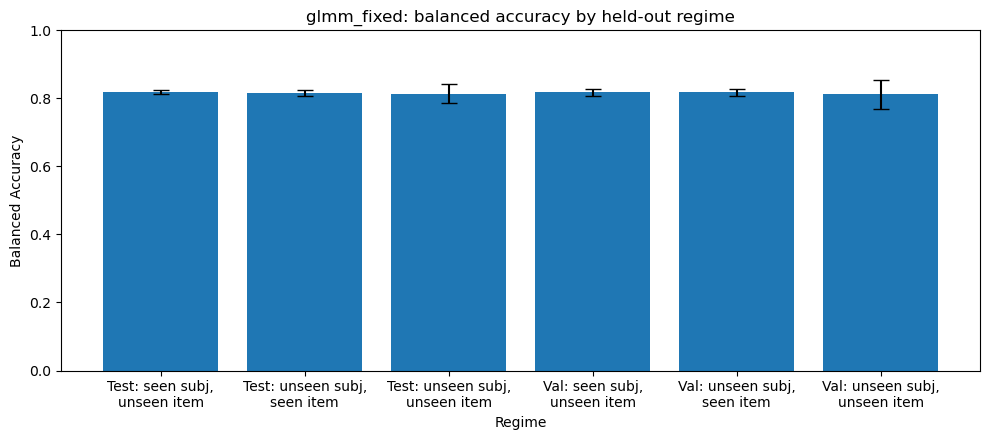

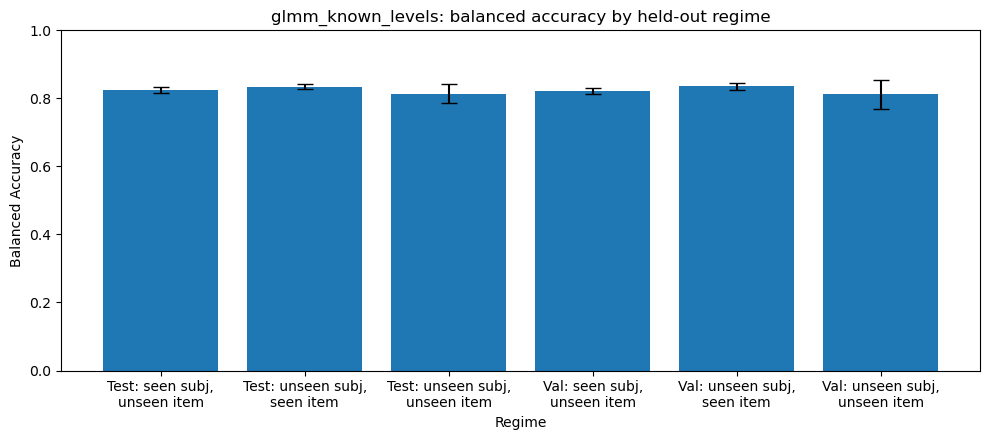

In [6]:
for name in ["glmm_fixed", "glmm_known_levels"]:
    _, fig, ax = plot_cv_metric_by_regime_pretty(cv_out, model_name=name, figsize=(10, 4.5))
    ax.set_title(f"{name}: balanced accuracy by held-out regime")
    plt.show()

### Side by side, on Study 1 and Study 2
*`plots.model_comparison.plot_model_comparison`, fed from the run above*

The paper's comparison figure with the three models in it. On Study 1, by the cross-validation
above. On Study 2 (KnowQA), after one fit on every Study 1 trial, scored on every KnowQA trial:
every KnowQA participant is new, so the GLMM is scored on its fixed effects only. Study 2 is one
fit and one test set, so its bars have no interval. The bars start at chance (0.5).

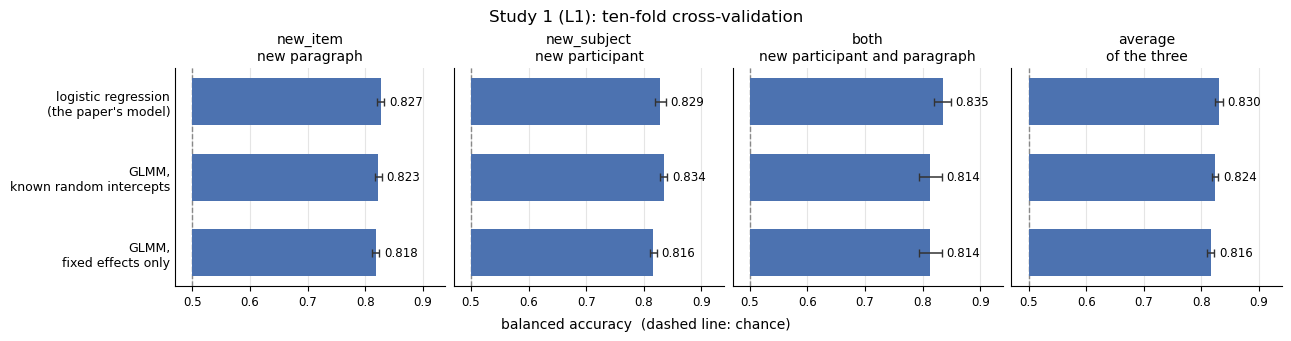

test,new_item,new_subject,both,average
model,,,,
glmm_fixed,0.818,0.816,0.814,0.816
glmm_known_levels,0.823,0.834,0.814,0.824
logreg,0.827,0.829,0.835,0.830


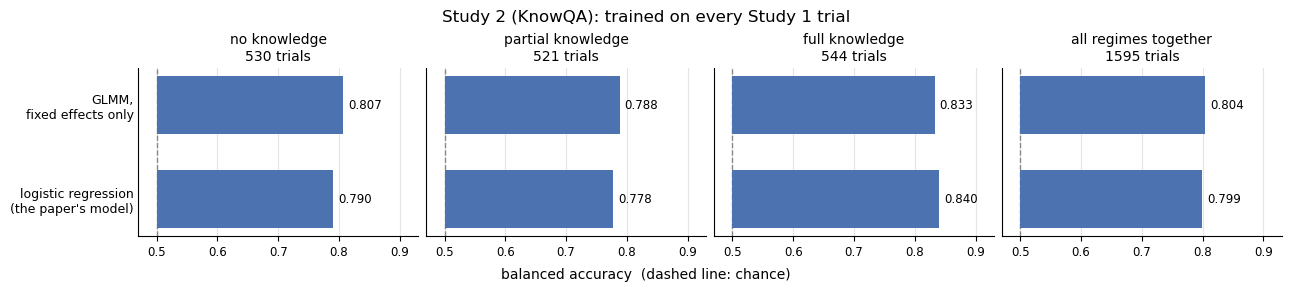

test,no knowledge,partial knowledge,full knowledge,all
model,,,,
glmm_fixed,0.807,0.788,0.833,0.804
logreg,0.790,0.778,0.840,0.799


In [7]:
l1 = summarize_cv_results_by_novelty(cv_out)
scores = [pd.DataFrame({
    "dataset": "l1", "test": l1["novelty"], "model": l1["model"], "n_features": len(HEADLINE),
    "balanced_accuracy": l1["mean_metric"], "ci_low": l1["ci_low"], "ci_high": l1["ci_high"],
    "n_folds": l1["n_folds"], "n_scored": l1["total_n_eval"], "note": "",
})]

# One fit on every Study 1 trial. The GLMM fitted here is also section 3's.
full_fits = {
    "logreg": TrialLevelLogRegModel(),
    "glmm_fixed": TrialLevelJuliaGLMERModel(name="glmm_fixed", text_col=TEXT, predict_with="fixed"),
}
knowqa_df = D.load_showcase_frame(verbose=False)
for name, model in full_fits.items():
    model.fit(trial_df, target_col=Con.IS_CORRECT_COLUMN, feature_cols=HEADLINE)
    scored = D.attach_predictions(knowqa_df, model, feature_cols=HEADLINE, verbose=False)
    metrics = D.prediction_metrics_by_regime(scored)
    scores.append(pd.DataFrame({
        "dataset": "knowqa", "test": metrics[D.REGIME_COL], "model": name,
        "n_features": len(HEADLINE), "balanced_accuracy": metrics["balanced_accuracy"],
        "ci_low": np.nan, "ci_high": np.nan, "n_folds": np.nan, "n_scored": metrics["n"], "note": "",
    }))
comparison = {"scores": pd.concat(scores, ignore_index=True), "folds": cv_out.summary_df}

LABELS = {
    "logreg": "logistic regression\n(the paper's model)",
    "glmm_fixed": "GLMM,\nfixed effects only",
    "glmm_known_levels": "GLMM,\nknown random intercepts",
}
for ds in TESTS:   # "l1", then "knowqa"
    plot_model_comparison(comparison, dataset=ds, labels=LABELS)
    plt.show()
    shown = comparison["scores"].query("dataset == @ds")
    display(shown.pivot(index="model", columns="test", values="balanced_accuracy")[TESTS[ds]].round(3))

## 3. The coefficients: one fit on all trials

The GLMM fitted on all 19,436 trials (the one scored on Study 2 above). Features are standardised,
so each coefficient is the change in log-odds of a correct answer for one standard deviation of the
feature, with the participant and the item held fixed; positive means "more of this, more likely
correct". The intervals are Wald intervals from the model's own standard errors, which account for
trials sharing a participant or an item through the random intercepts.

Beside it, two references: the logistic regression fitted on the same trials (with
participant-clustered Wald intervals, which are quick; the paper's bootstrap intervals are in the
logistic-regression notebook), and the same GLMM fitted **without** the class weights, which is
the plain maximum-likelihood fit. Its intercept is different by design; its slopes and variances
show what the weights change.

In [8]:
glmm_full = full_fits["glmm_fixed"]
glmm_unweighted = TrialLevelJuliaGLMERModel(name="glmm_unweighted", text_col=TEXT, class_weight=None)
glmm_unweighted.fit(trial_df, target_col=Con.IS_CORRECT_COLUMN, feature_cols=HEADLINE)

coefs = {
    "logreg": full_fits["logreg"].get_coef_summary(
        trial_df, feature_cols=HEADLINE, ci_method="wald", ci_cluster="cluster",
    ),
    "glmm": glmm_full.get_coef_summary(),
    "glmm_unweighted": glmm_unweighted.get_coef_summary(),
}
order = list(coefs["glmm"]["feature"])   # largest |coefficient| in the GLMM first
side_by_side = pd.concat(
    {name: c.set_index("feature").loc[order, ["coef", "ci_low", "ci_high"]] for name, c in coefs.items()},
    axis=1,
)
side_by_side.round(3)

logreg                  glmm         \
                                     coef ci_low ci_high   coef ci_low   
feature                                                                  
area_dwell_proportion__correct      0.940  0.843   1.037  1.474  1.375   
last_before_confirm_correct         1.213  1.125   1.300  1.454  1.388   
mean_fixations_count__wrong_mean   -0.497 -0.598  -0.396 -0.568 -0.670   
num_label_visits__contrast          0.364  0.244   0.484  0.372  0.263   
num_label_visits__correct          -0.268 -0.406  -0.130 -0.288 -0.410   
has_xyx                            -0.231 -0.284  -0.178 -0.269 -0.324   
area_dwell_proportion__question     0.202  0.124   0.279  0.234  0.161   
mean_max_fix_pupil_size_z__correct -0.182 -0.239  -0.126 -0.225 -0.280   
last_before_confirm_question        0.143  0.093   0.193  0.163  0.117   
ANSWER_PRESS_NUMBER                -0.107 -0.159  -0.054 -0.147 -0.207   
mean_fixations_count__question     -0.190 -0.272  -0.108 -0.127 -0.208   
skip_rate__correct                 -0.241 -0.310  -0.172 -0.110 -0.183   

                                           glmm_unweighted                 
                                   ci_high            coef ci_low ci_high  
feature                                                                    
area_dwell_proportion__correct       1.573           1.325  1.217   1.433  
last_before_confirm_correct          1.521           1.388  1.307   1.470  
mean_fixations_count__wrong_mean    -0.466          -0.505 -0.603  -0.407  
num_label_visits__contrast           0.482           0.331  0.218   0.444  
num_label_visits__correct           -0.165          -0.116 -0.241   0.009  
has_xyx                             -0.214          -0.292 -0.352  -0.232  
area_dwell_proportion__question      0.306           0.239  0.156   0.322  
mean_max_fix_pupil_size_z__correct  -0.171          -0.227 -0.287  -0.167  
last_before_confirm_question         0.210           0.159  0.105   0.213  
ANSWER_PRESS_NUMBER                 -0.087          -0.118 -0.176  -0.060  
mean_fixations_count__question      -0.046          -0.148 -0.230  -0.065  
skip_rate__correct                  -0.036          -0.094 -0.171  -0.017

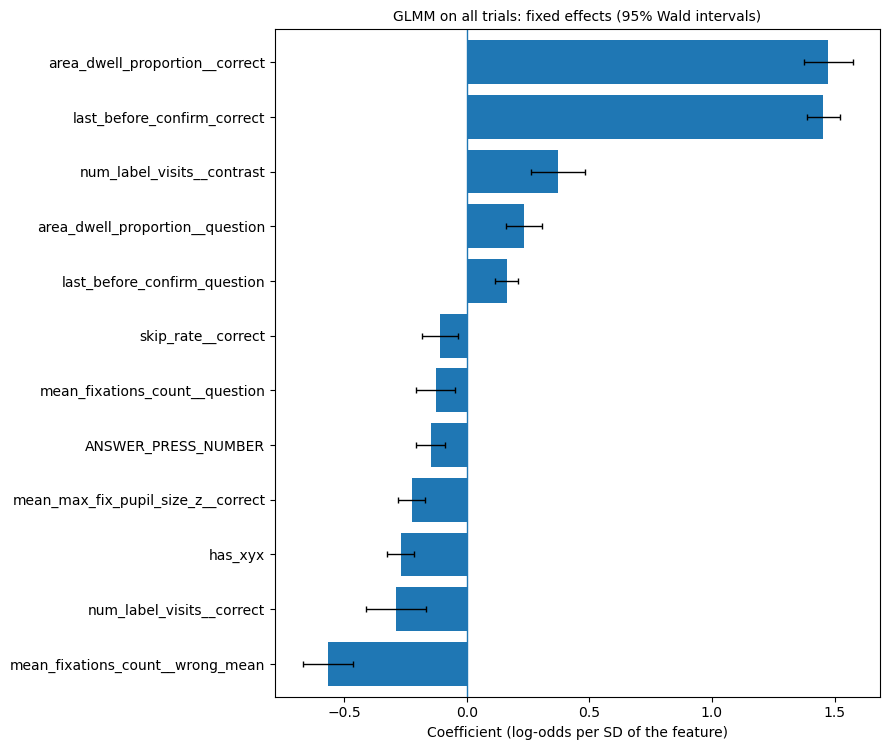

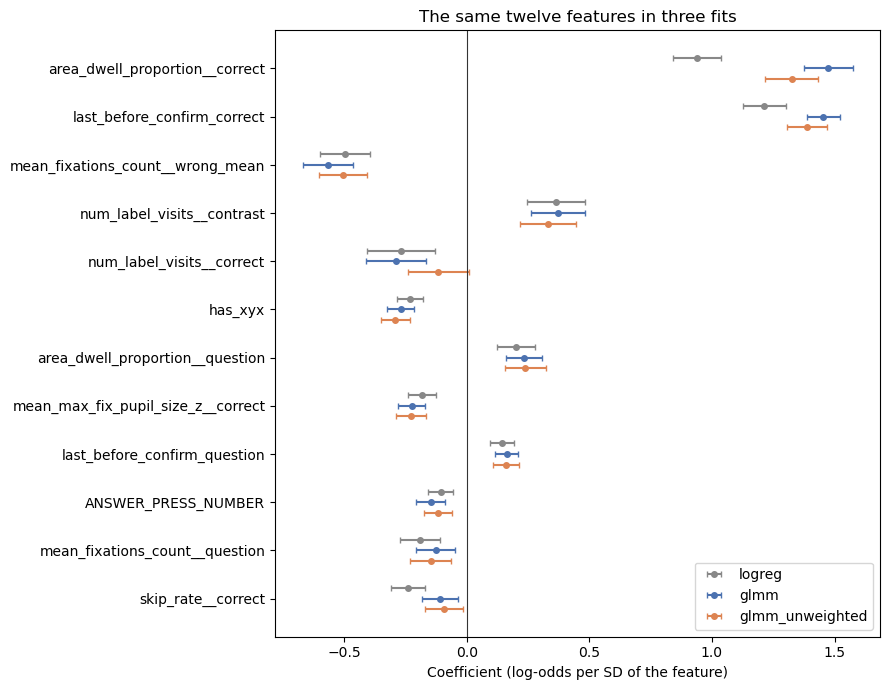

In [9]:
plot_coef_summary_barh(
    coefs["glmm"],
    significant_only=False,
    title="GLMM on all trials: fixed effects (95% Wald intervals)",
    xlabel="Coefficient (log-odds per SD of the feature)",
    ylabel="",
    save=False,
)

# The three fits' estimates per feature, on one axis.
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(order))[::-1]
styles = {"logreg": "#888888", "glmm": "#4C72B0", "glmm_unweighted": "#DD8452"}
for offset, (name, color) in zip((0.22, 0.0, -0.22), styles.items()):
    c = coefs[name].set_index("feature").loc[order]
    ax.errorbar(
        c["coef"], y + offset,
        xerr=[c["coef"] - c["ci_low"], c["ci_high"] - c["coef"]],
        fmt="o", ms=4, capsize=2, color=color, label=name,
    )
ax.axvline(0, color="#333333", lw=0.8)
ax.set_yticks(y, order)
ax.set_xlabel("Coefficient (log-odds per SD of the feature)")
ax.set_title("The same twelve features in three fits")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**How much sits with the person and with the item.** The estimated standard deviation of each
random intercept, and its share of the variance on the latent (log-odds) scale: the intercept's
variance over itself, the other intercept and π²/3, the fixed variance of the logistic
distribution. This is the usual latent-scale intraclass correlation for a logistic model. Read it
from the unweighted fit; the weighted fit's values are enlarged by the weights.

In [10]:
def variance_row(model):
    sd = model.get_variance_components().set_index("group")["sd"]
    var_p, var_i = sd[Con.PARTICIPANT_ID] ** 2, sd[TEXT] ** 2
    latent = var_p + var_i + np.pi ** 2 / 3
    return {
        "sd_participant": sd[Con.PARTICIPANT_ID], "sd_item": sd[TEXT],
        "share_participant": var_p / latent, "share_item": var_i / latent,
        "converged": model.converged_, "singular": model.is_singular_,
    }

pd.DataFrame({
    "glmm (class-weighted)": variance_row(glmm_full),
    "glmm_unweighted": variance_row(glmm_unweighted),
}).T

,sd_participant,sd_item,share_participant,share_item,converged,singular
glmm (class-weighted),0.913403,1.614913,0.123929,0.387388,True,False
glmm_unweighted,0.739106,1.183485,0.104315,0.267461,True,False


The random intercepts themselves, from the class-weighted fit: one per participant and one per
item, in log-odds. They are shrunk towards 0, more so for levels with few trials, and their spread
is the standard deviation above.

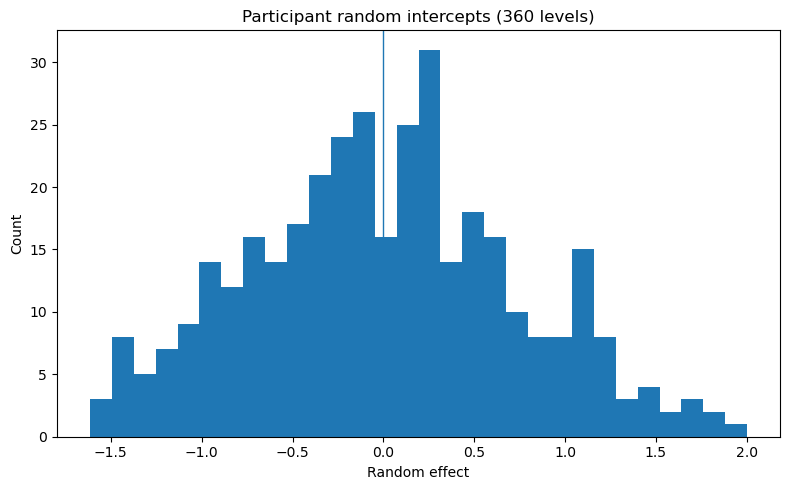

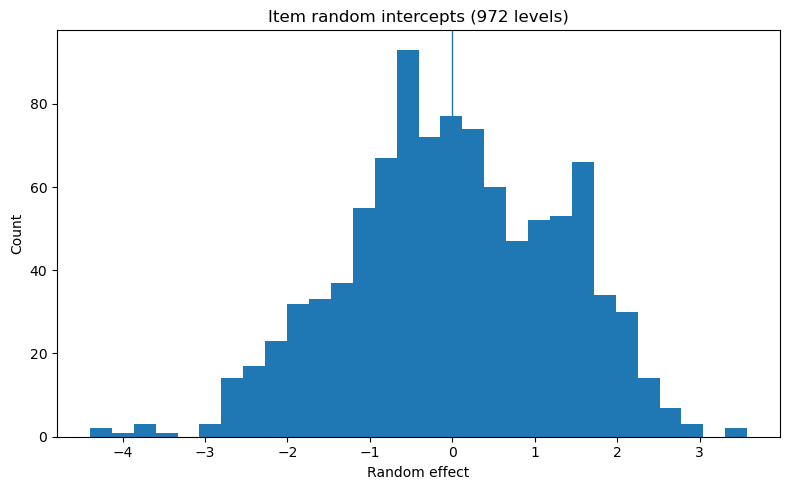

In [11]:
rfx = glmm_full.get_random_effects()
fig_titles = {Con.PARTICIPANT_ID: "Participant random intercepts", TEXT: "Item random intercepts"}
for group, table in rfx.items():
    plot_random_effects_distribution(table, title=f"{fig_titles[group]} ({len(table)} levels)", save=False)
    plt.show()

## 4. One train/test split, to see what the model outputs

As in the logistic-regression notebook: the GLMM is fitted on fold 0's training trials and scored
on that fold's test trials of new participants reading new paragraphs. One split, not the reported
numbers. With both the participant and the item new, the two scoring rules are the same, so this
is `glmm_fixed`. It prints the scores and draws the confusion matrix (as shares of each true
outcome, and as counts), the predicted probability of a correct answer split by what actually
happened, and the coefficients of this one fit (all, and those whose interval excludes 0).

Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv


MODEL: glmm_fixed
----------------------------------------------------------------------
Number of test trials: 720
Accuracy: 0.879
Balanced accuracy: 0.805
Positive (correct) trials: 625
Negative (incorrect) trials: 95

Precision / Recall / F1 (per class):
         precision  recall    f1  support
class_0      0.532   0.705 0.606       95
class_1      0.953   0.906 0.929      625

Averages:
  macro    P/R/F1: 0.742 / 0.805 / 0.767
  weighted P/R/F1: 0.897 / 0.879 / 0.886

ROC-AUC: 0.915
Average precision (PR-AUC): 0.986

Formula: is_correct ~ 1 + area_dwell_proportion__correct + area_dwell_proportion__question + skip_rate__correct + has_xyx + ANSWER_PRESS_NUMBER + num_label_visits__correct + num_label_visits__contrast + mean_fixations_count__question + mean_fixations_count__wrong_mean + mean_max_fix_pupil_size_z__correct + last_before_confirm_correct + last_before_confirm_question + (1 | participant_id) + (1 | text_id_with_q)
Optimiser: FTOL_REACHED   singular: False


training trials: 11,711   held-out test trials: 720


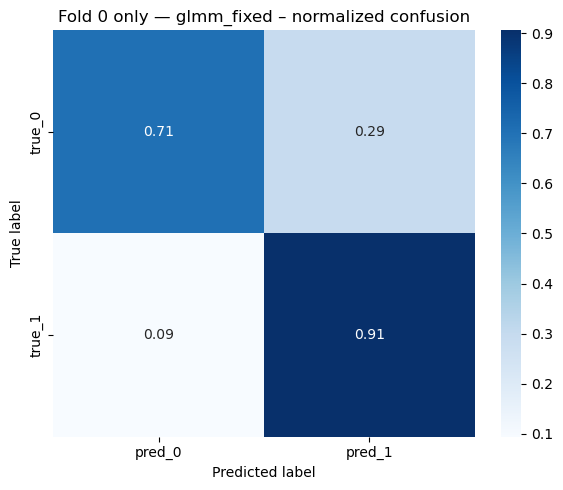

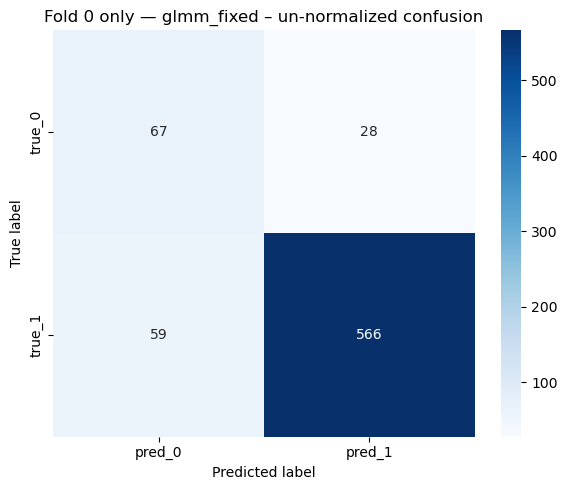

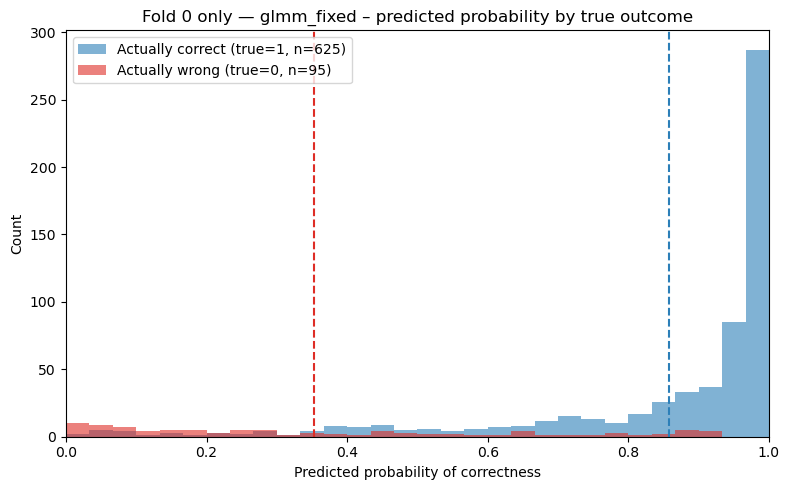

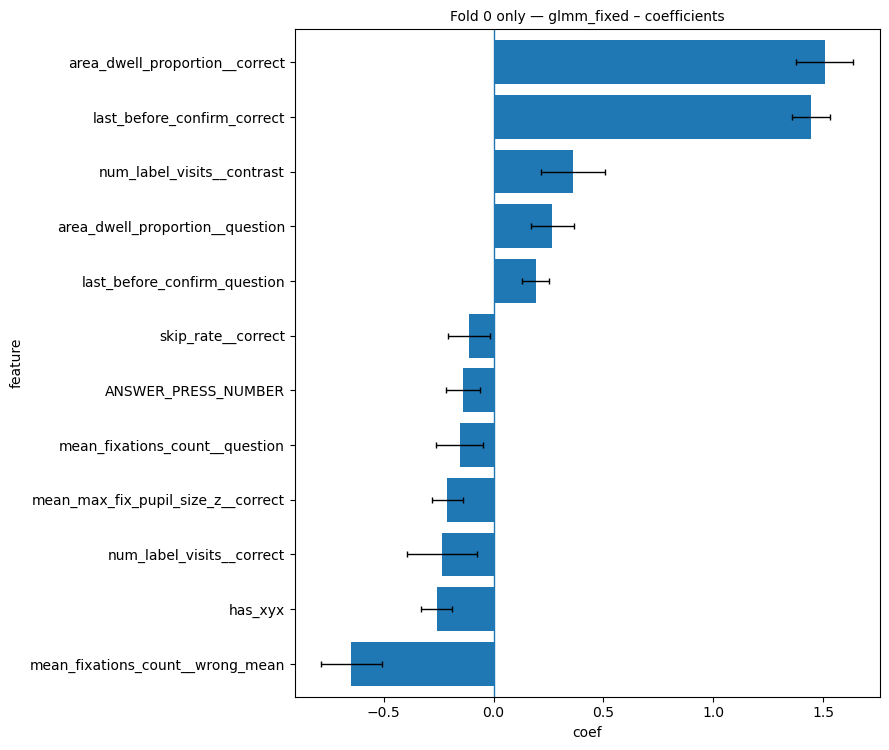

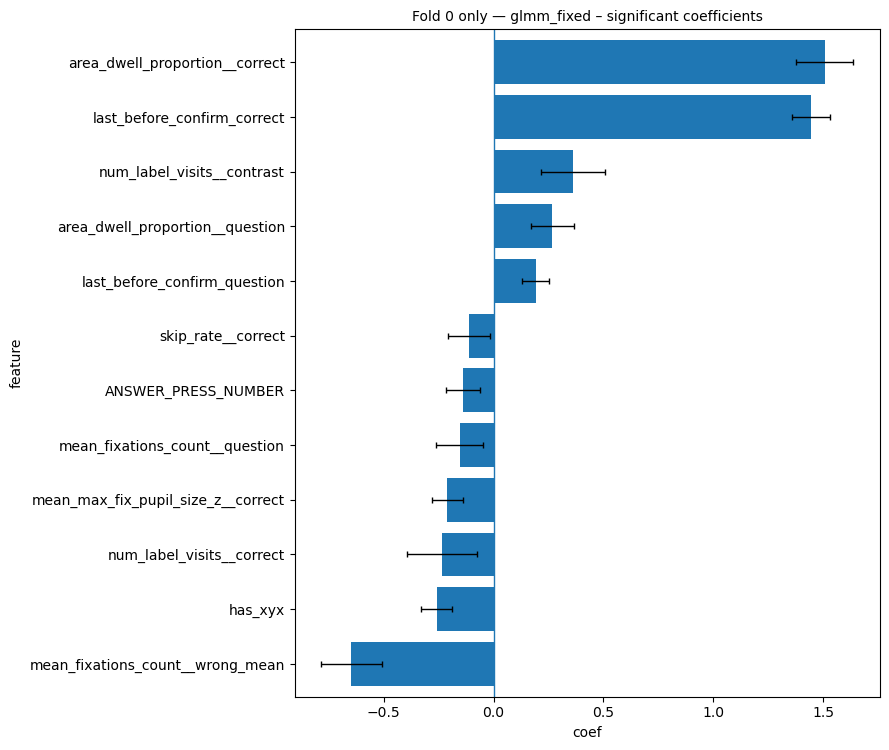

In [12]:
split = run_full_features_correctness_julia_glmer_bundle(
    word_df,
    ["both"],                 # held out: new participants reading new paragraphs
    model=TrialLevelJuliaGLMERModel(name="glmm_fixed", text_col=TEXT, predict_with="fixed"),
    test_split="test",
    fold=0,
    feature_cols=HEADLINE,
    title_prefix="Fold 0 only",
    save=False,
)
print(f"training trials: {len(split['train_df']):,}   held-out test trials: {len(split['test_df']):,}")

**Where the two scoring rules differ.** The same fold, now scored on its test trials of *known*
participants reading new paragraphs. One fit, scored twice: with every random intercept at 0, and
with each participant's own intercept added. The second moves a trial's probability by how
accurate that person was in training. Whether that makes the probability a better proxy for
confidence, or only a better guess of the person's accuracy, is the question this figure is for.

Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv


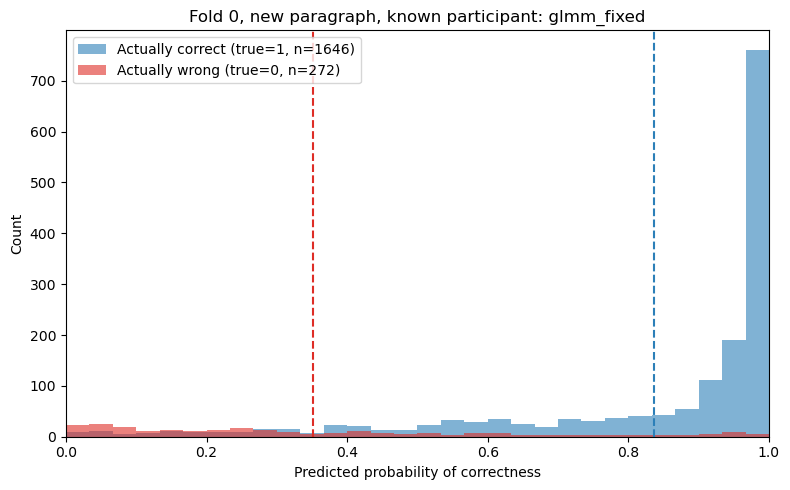

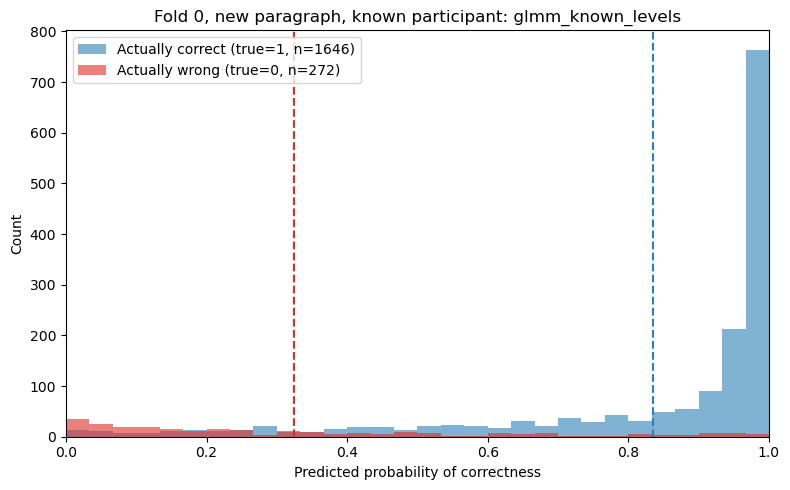

In [13]:
train_df, test_df, _ = build_train_test_trial_dfs(word_df, ["new_item"], test_split="test", fold=0)
model = TrialLevelJuliaGLMERModel(name="glmm", text_col=TEXT)
model.fit(train_df, target_col=Con.IS_CORRECT_COLUMN, feature_cols=HEADLINE)

y_true = test_df[Con.IS_CORRECT_COLUMN].astype(int).to_numpy()
for predict_with in ["fixed", "known_levels"]:
    model.predict_with = predict_with
    plot_predicted_probability_hist(
        y_true, model.predict_proba(test_df),
        title=f"Fold 0, new paragraph, known participant: glmm_{predict_with}",
        save=False,
    )
    plt.show()